## Zadanie 1

In [1]:
!nvidia-smi

Thu Oct 22 10:55:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import numpy as np
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
start = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end = time.time()
print(f"CPU: {end - start:.5f} sekund.")

CPU: 0.01865 sekund.


In [4]:
import cupy as cp
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)
start = time.time()
C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()  # Synchronizacja z GPU
end = time.time()
print(f"GPU: {end - start:.5f} sekund.")

GPU: 0.01773 sekund.


## Zadanie 2

In [5]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda

In [6]:
import pycuda.driver as cuda
cuda.init()
ctx = cuda.Device(0).retain_primary_context()
ctx.push()
from pycuda.compiler import SourceModule

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

def mnozenie_kernel(A_cpu, B_cpu):
    N = A_cpu.shape[0]
    C_cpu = np.empty((N, N), np.float32)
    A_gpu = cuda.mem_alloc(A_cpu.nbytes)
    B_gpu = cuda.mem_alloc(B_cpu.nbytes)
    C_gpu = cuda.mem_alloc(C_cpu.nbytes)
    cuda.memcpy_htod(A_gpu, A_cpu)
    cuda.memcpy_htod(B_gpu, B_cpu)
    block_size = (32, 32, 1)
    grid_size = (int(N/32), int(N/32), 1)
    matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
    cuda.Context.synchronize()
    cuda.memcpy_dtoh(C_cpu, C_gpu)
    del A_gpu, B_gpu, C_gpu
    return C_cpu

N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
start = time.time()
C_cpu = mnozenie_kernel(A_cpu, B_cpu)
end = time.time()
print(f"Własny kernel: {end - start:.5f} sekund.")

Własny kernel: 0.02530 sekund.


## Zadanie 3

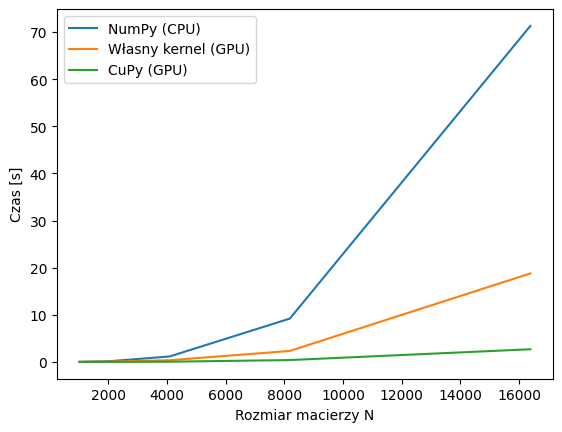

In [18]:
import matplotlib.pyplot as plt

sizes = [1024, 2048, 4096, 8192, 16384]
#sizes = [128, 256, 512, 1024, 2048]
#sizes = [32, 64, 128, 256, 512]
t_cpu, t_cupy, t_kernel = [], [], []

for N in sizes:
    A = np.random.rand(N, N).astype(np.float32)
    B = np.random.rand(N, N).astype(np.float32)

    start = time.time()
    np.matmul(A, B)
    t_cpu.append(time.time() - start)

    start = time.time()
    mnozenie_kernel(A, B)
    t_kernel.append(time.time() - start)

    start = time.time()
    Ag = cp.array(A)
    Bg = cp.array(B)
    cp.matmul(Ag, Bg)
    cp.cuda.Stream.null.synchronize()
    t_cupy.append(time.time() - start)



plt.plot(sizes, t_cpu, label="NumPy (CPU)")
plt.plot(sizes, t_kernel, label="Własny kernel (GPU)")
plt.plot(sizes, t_cupy, label="CuPy (GPU)")

plt.legend()
plt.xlabel("Rozmiar macierzy N")
plt.ylabel("Czas [s]")
plt.show()